# Automatic chord recognition

This notebook presents the hierarchical chord-recognition system, reproduces its RWC evaluation, and provides an in-notebook audio player with synchronized chord predictions.

The default system is a hierarchical CQT72 CNN followed by a second-order HSMM. The CNN predicts root, quality, seventh, and extension separately; the HSMM uses the current emissions and the two previous chords to select a musically plausible sequence.

## 1. Setup

**First run:** execute only the setup cell below. It creates `.venv`, installs the required packages, and registers **Python (DT2470 submission)** as a notebook kernel. Select that kernel in Jupyter or VS Code, then choose **Run All Cells**. On later runs, select the same kernel and run normally. The setup is idempotent and reinstalls packages only when `requirements.txt` changes.

In [1]:
from pathlib import Path
import json
import os
import subprocess
import sys

cwd = Path.cwd().resolve()
ROOT = cwd if (cwd / 'models/best_model.pt').is_file() else cwd / 'submission'
assert (ROOT / 'models/best_model.pt').is_file(), 'Could not find submission/models/best_model.pt'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from scripts.environments import ensure_application_environment
venv_python = ensure_application_environment()
venv_dir = ROOT / '.venv'
using_project_venv = Path(sys.prefix).resolve() == venv_dir.resolve()

if not using_project_venv:
    subprocess.run(
        [str(venv_python), '-m', 'ipykernel', 'install', '--user',
         '--name', 'dt2470-submission', '--display-name', 'Python (DT2470 submission)'],
        check=True,
    )
    print('\nEnvironment ready. Now select the kernel: Python (DT2470 submission)')
    print('Then run the notebook again with Run All Cells.')
else:
    import librosa
    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd
    from IPython.display import HTML, display

    env = os.environ.copy()
    env['PYTHONPATH'] = str(ROOT)
    print('Environment ready:', venv_dir)
    print('Submission folder:', ROOT)

Environment ready: /Users/eliasvarling/dev/musik_informatik/dt2470-project/submission/.venv
Submission folder: /Users/eliasvarling/dev/musik_informatik/dt2470-project/submission


## 2. Architecture and musical motivation

A chord is not only a single class. Its root describes the harmonic centre, quality describes its basic colour, the seventh changes its function and tension, and extensions add further colour. Predicting these parts with separate but connected heads gives the model useful structure and makes errors easier to interpret.

The CQT keeps pitch relationships visible. The CNN turns short time-frequency windows into probabilities. The second-order HSMM smooths those probabilities over time while modelling chord transitions and durations. This avoids isolated one-frame chord changes and captures common progressions such as tonic–predominant–dominant movement. See `ARCHITECTURE.md` for the complete description.

## 3. Optional training demonstration

The command below is the complete training entry point. It requires the cached CQT feature directory and can take a while, so leave it commented out for a quick presentation.

In [2]:
# subprocess.run([sys.executable, 'training/train_hierarchical_cnn.py',
#                 '--feature-dir', 'data/features_cqt72_v1',
#                 '--reference-checkpoint', 'models/best_model.pt',
#                 '--split-manifest', 'models/split_manifest.json',
#                 '--epochs', '30'], cwd=ROOT, check=True)

## 4. RWC evaluation

The evaluation uses the fixed 15-song test split in `training/evaluate_rwc.py`. **Frame accuracy** gives every analysis frame equal weight. **Duration-weighted accuracy** gives each frame its actual time span, so it represents the fraction of annotated listening time recognized correctly. Results are shown at three levels: root, root + quality, and the complete root + quality + seventh label.

In [14]:
FEATURE_DIR = ROOT / 'features'
assert FEATURE_DIR.is_dir(), f'Feature directory is missing: {FEATURE_DIR}'
subprocess.run(
    [sys.executable, 'training/evaluate_rwc.py',
     '--feature-dir', str(FEATURE_DIR),
     '--checkpoint', 'models/best_model.pt'],
    cwd=ROOT, env=env, check=True,
)
report = json.loads((ROOT / 'output/rwc_test_evaluation.json').read_text())
print(f"Evaluated {len(report['per_song'])} songs.")

{
  "root_accuracy": 0.8831816316825667,
  "root_quality_accuracy": 0.8268141329396921,
  "root_quality_seventh_accuracy": 0.7008948036392126,
  "song_root_percent": 0.899036990068324,
  "song_root_quality_percent": 0.843932939928713,
  "song_root_quality_seventh_percent": 0.7114024505937807
}
Wrote output/rwc_test_evaluation.json
Wrote readable per-frame comparisons to output/rwc_comparison
Evaluated 15 songs.


### Aggregate metrics

The table and chart contain every metric written by the evaluator. Values are macro averages: every test song contributes equally.

Evaluation,Chord components,Score
Frame accuracy,Root,88.32%
Frame accuracy,Root + quality,82.68%
Frame accuracy,Root + quality + seventh,70.09%
Duration-weighted accuracy,Root,89.90%
Duration-weighted accuracy,Root + quality,84.39%
Duration-weighted accuracy,Root + quality + seventh,71.14%


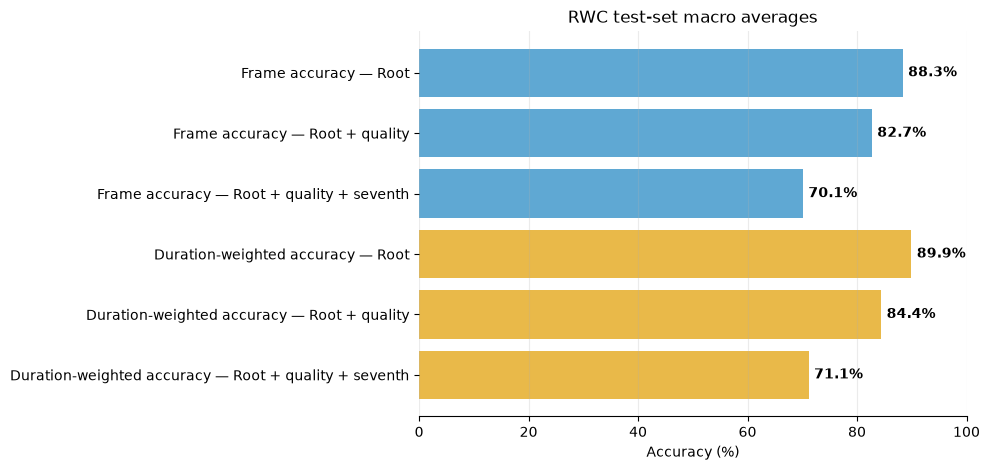

In [15]:
metric_info = [
    ('root_accuracy', 'Root', 'Frame accuracy'),
    ('root_quality_accuracy', 'Root + quality', 'Frame accuracy'),
    ('root_quality_seventh_accuracy', 'Root + quality + seventh', 'Frame accuracy'),
    ('song_root_percent', 'Root', 'Duration-weighted accuracy'),
    ('song_root_quality_percent', 'Root + quality', 'Duration-weighted accuracy'),
    ('song_root_quality_seventh_percent', 'Root + quality + seventh', 'Duration-weighted accuracy'),
]
metrics = report['cnn_macro_average']
aggregate = pd.DataFrame([
    {'Evaluation': evaluation, 'Chord components': components, 'Score': metrics[key]}
    for key, components, evaluation in metric_info
])
display(aggregate.style.hide(axis='index').format({'Score': '{:.2%}'}).bar(subset=['Score'], vmin=0, vmax=1, color='#66c7a5'))

fig, ax = plt.subplots(figsize=(10, 4.8))
plot_labels = [f'{row.Evaluation} — {row["Chord components"]}' for _, row in aggregate.iterrows()]
values = 100 * aggregate['Score'].to_numpy()
colors = ['#5fa8d3'] * 3 + ['#e9b949'] * 3
bars = ax.barh(plot_labels[::-1], values[::-1], color=colors[::-1])
ax.bar_label(bars, fmt='%.1f%%', padding=4, fontweight='bold')
ax.set(xlim=(0, 100), xlabel='Accuracy (%)', title='RWC test-set macro averages')
ax.grid(axis='x', alpha=.25)
ax.spines[['top', 'right', 'left']].set_visible(False)
plt.tight_layout()
plt.show()

### Per-song metrics

This view exposes all six metrics for every test song, making the spread behind the macro average visible.

,Frame: R,Frame: R+Q,Frame: R+Q+7,Duration: R,Duration: R+Q,Duration: R+Q+7
Song,,,,,,
RWC P037,80.19%,68.87%,68.87%,87.77%,73.58%,73.58%
RWC P034,89.17%,87.50%,73.33%,88.36%,87.84%,75.36%
RWC P090,89.68%,85.71%,74.60%,90.80%,87.76%,78.37%
RWC P089,84.11%,77.57%,70.09%,80.29%,75.81%,65.51%
RWC P003,92.90%,89.68%,80.00%,90.92%,78.78%,70.97%
RWC P060,100.00%,78.82%,55.29%,100.00%,79.90%,44.58%
RWC P072,77.31%,75.63%,56.30%,80.40%,78.84%,59.19%
RWC P017,90.08%,87.60%,74.38%,92.32%,90.71%,77.38%
RWC P035,91.51%,77.36%,68.87%,91.93%,81.04%,72.95%


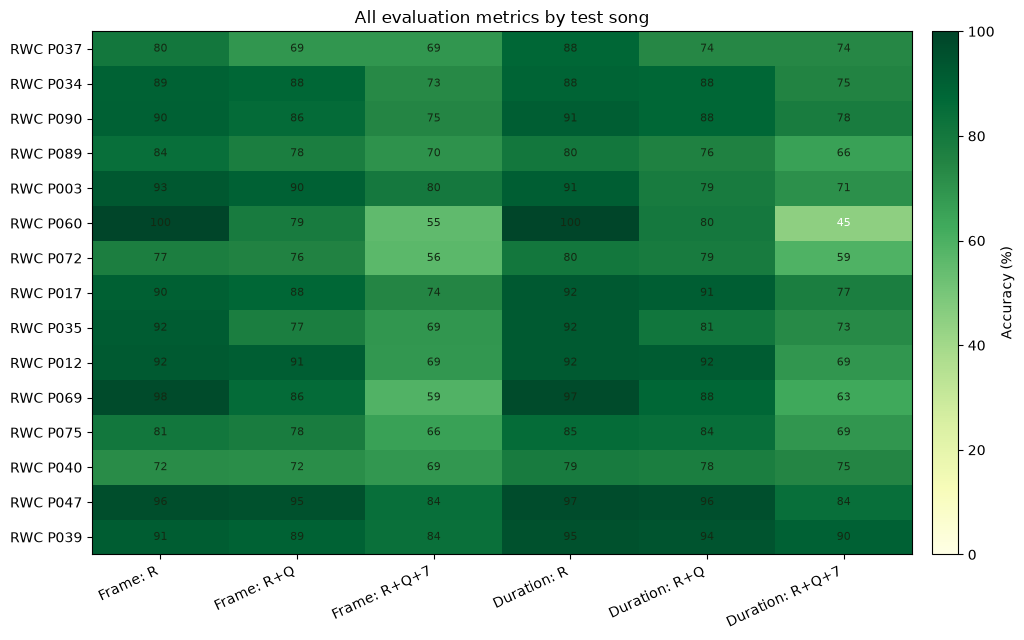

In [16]:
short_names = ['Frame: R', 'Frame: R+Q', 'Frame: R+Q+7', 'Duration: R', 'Duration: R+Q', 'Duration: R+Q+7']
per_song = pd.DataFrame(
    [[f"RWC P{item['song']:03d}"] + [item['cnn'][key] for key, _, _ in metric_info]
     for item in report['per_song']],
    columns=['Song'] + short_names,
).set_index('Song')
display(per_song.style.format('{:.2%}').background_gradient(cmap='YlGn', vmin=0, vmax=1))

fig, ax = plt.subplots(figsize=(11, 6.5))
image = ax.imshow(100 * per_song.to_numpy(), cmap='YlGn', vmin=0, vmax=100, aspect='auto')
ax.set_xticks(range(len(short_names)), short_names, rotation=25, ha='right')
ax.set_yticks(range(len(per_song)), per_song.index)
for row in range(len(per_song)):
    for column in range(len(short_names)):
        value = 100 * per_song.iloc[row, column]
        ax.text(column, row, f'{value:.0f}', ha='center', va='center', fontsize=8, color='white' if value < 55 else '#132a13')
fig.colorbar(image, ax=ax, label='Accuracy (%)', pad=.02)
ax.set_title('All evaluation metrics by test song')
plt.tight_layout()
plt.show()

## 5. Listen to and visualize a song

The default is an annotated RWC song. Inference writes the chord sequence, then the next cells show the waveform, the model prediction, and ground truth on the same time axis. The embedded player keeps the audio, live predicted chord, live ground-truth chord, and both colored timelines synchronized; click any chord block to seek.

In [17]:
supported_audio = {'.wav', '.mp3', '.flac', '.ogg'}
audio_files = [path for path in sorted((ROOT / 'audio').glob('*'))
               if path.suffix.lower() in supported_audio and path.stat().st_size > 0]
display(pd.DataFrame({
    'Available song': [path.stem for path in audio_files],
    'Format': [path.suffix.lower().lstrip('.').upper() for path in audio_files],
    'Size (MB)': [path.stat().st_size / 1_000_000 for path in audio_files],
}).style.hide(axis='index').format({'Size (MB)': '{:.1f}'}))

Available song,Format,Size (MB)
RWC_P003,WAV,34.1
RWC_P017,WAV,42.2
beatles_something,FLAC,33.2


In [18]:
# Choose any listed song. Annotated RWC examples show ground truth; other songs run prediction-only.
song = 'RWC_P017'
assert any(song in {path.name, path.stem} for path in audio_files), f'Audio not found: {song}'
subprocess.run(
    [sys.executable, 'main.py', '--source', 'local', '--input-dir', 'audio',
     '--cnn-checkpoint', 'models/best_model.pt',
     '--language-model', 'models/harmonic_model.pkl',
     '--split-manifest', 'models/split_manifest.json',
     '--song', song, '--non-interactive'],
    cwd=ROOT, env=env, check=True,
)
summary = json.loads((ROOT / 'output/summary.json').read_text())
result = next(item for item in summary if item['song'] == Path(song).stem)
audio_path = Path(result['audio'])
if not audio_path.is_absolute():
    audio_path = ROOT / audio_path
timeline_path = Path(result['prediction_csv'])
if not timeline_path.is_absolute():
    timeline_path = ROOT / timeline_path
timeline = pd.read_csv(timeline_path)
annotation_path = ROOT / 'annotations' / f'{audio_path.stem}.csv'
ground_truth = None
if annotation_path.is_file():
    ground_truth = pd.read_csv(annotation_path, sep=';').rename(
        columns={'t_start': 'start_seconds', 't_end': 'end_seconds'},
    )
    print(f"Recognized {len(timeline)} chord events and loaded {len(ground_truth)} ground-truth events for {audio_path.name}.")
else:
    print(f"Recognized {len(timeline)} chord events for {audio_path.name}; no ground truth is available.")


Running hierarchical CNN + order-2 HSMM: RWC_P017
  wrote output/hierarchical_cnn_hsmm/RWC_P017_chords.csv
  wrote output/hierarchical_cnn_hsmm/RWC_P017_chords.json
  open output/RWC_P017_viewer.html to listen with live chords

Finished 1 song(s) with the hierarchical model.
Summary: output/summary.json
Recognized 120 chord events and loaded 125 ground-truth events for RWC_P017.wav.


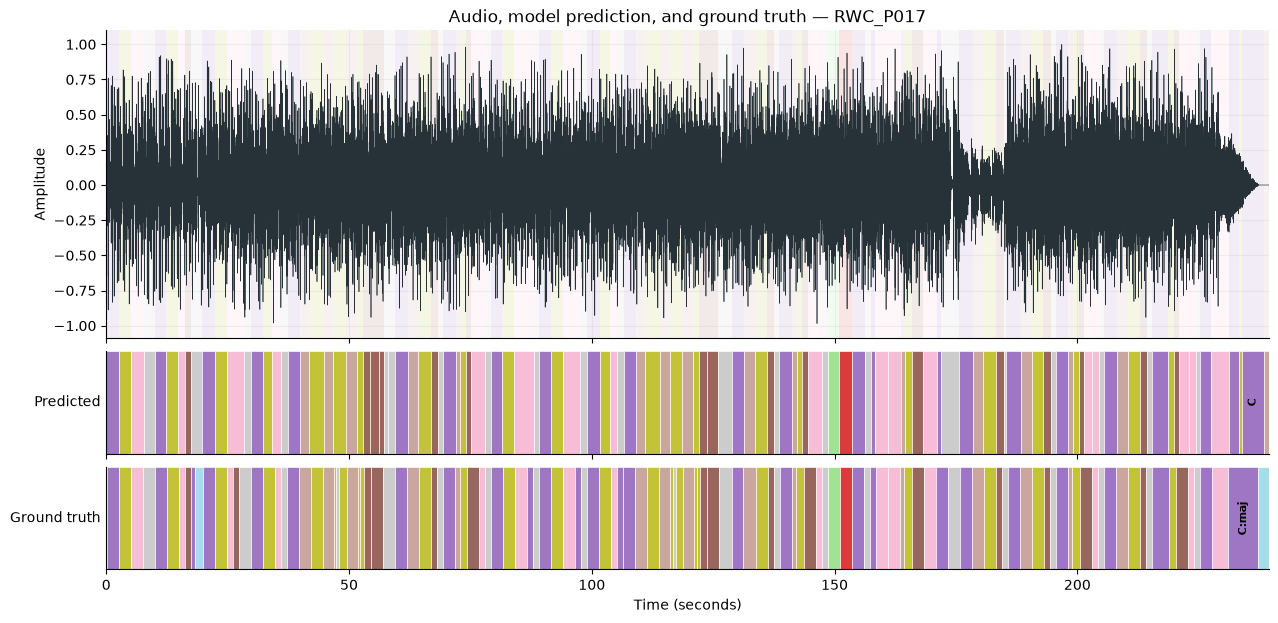

In [19]:
# A lightweight waveform is sufficient for display and keeps this cell responsive.
waveform, sample_rate = librosa.load(audio_path, sr=8_000, mono=True)
max_points = 60_000
stride = max(1, len(waveform) // max_points)
times = np.arange(0, len(waveform), stride) / sample_rate
duration = len(waveform) / sample_rate

roots = ['C#', 'Eb', 'F#', 'Ab', 'Bb', 'C', 'D', 'E', 'F', 'G', 'A', 'B', 'N']
palette = plt.get_cmap('tab20')(np.linspace(0, 1, len(roots)))
def chord_color(label):
    root = next((root for root in roots[:-1] if str(label).startswith(root)), 'N')
    return palette[roots.index(root)]

if ground_truth is not None:
    fig, (wave_ax, predicted_ax, truth_ax) = plt.subplots(3, 1, figsize=(15, 7), sharex=True,
        gridspec_kw={'height_ratios': [3, 1, 1], 'hspace': .08})
    plot_axes = (wave_ax, predicted_ax, truth_ax)
    title = f'Audio, model prediction, and ground truth — {audio_path.stem}'
else:
    fig, (wave_ax, predicted_ax) = plt.subplots(2, 1, figsize=(15, 5.5), sharex=True,
        gridspec_kw={'height_ratios': [3, 1], 'hspace': .08})
    truth_ax = None
    plot_axes = (wave_ax, predicted_ax)
    title = f'Audio and model prediction — {audio_path.stem}'
wave_ax.plot(times, waveform[::stride], color='#263238', linewidth=.45)
wave_ax.set(ylabel='Amplitude', title=title)
wave_ax.grid(alpha=.16)

label_threshold = max(2.5, duration / 55)
for event in timeline.itertuples(index=False):
    start, end, chord = event.start_seconds, event.end_seconds, str(event.chord)
    color = chord_color(chord)
    wave_ax.axvspan(start, end, color=color, alpha=.12, linewidth=0)
    predicted_ax.axvspan(start, end, color=color, alpha=.9, ec='white', lw=.5)
    if end - start >= label_threshold:
        predicted_ax.text((start + end) / 2, .5, chord, ha='center', va='center',
                      fontsize=8, fontweight='bold', rotation=90 if end - start < duration / 28 else 0)

if ground_truth is not None:
    for event in ground_truth.itertuples(index=False):
        start, end, chord = event.start_seconds, event.end_seconds, str(event.chord)
        display_chord = chord.replace(':maj', '').replace(':min', 'min')
        truth_ax.axvspan(start, end, color=chord_color(display_chord), alpha=.9, ec='white', lw=.5)
        if end - start >= label_threshold:
            truth_ax.text((start + end) / 2, .5, chord, ha='center', va='center',
                          fontsize=8, fontweight='bold', rotation=90 if end - start < duration / 28 else 0)

predicted_ax.set(xlim=(0, duration), ylim=(0, 1), yticks=[])
predicted_ax.set_ylabel('Predicted', rotation=0, ha='right', va='center')
if truth_ax is not None:
    truth_ax.set(xlim=(0, duration), ylim=(0, 1), yticks=[], xlabel='Time (seconds)')
    truth_ax.set_ylabel('Ground truth', rotation=0, ha='right', va='center')
else:
    predicted_ax.set_xlabel('Time (seconds)')
for axis in plot_axes:
    axis.spines[['top', 'right']].set_visible(False)
plt.show()

### Interactive audio and chord player

Run the cell below to open the player in a separate browser window. It always shows the synchronized model prediction and upcoming chords. When an annotation file is available, it also shows the live ground-truth chord and comparison timeline.

In [21]:
import webbrowser
from IPython.display import HTML, display

viewer_path = (ROOT / 'output' / f'{Path(song).stem}_viewer.html').resolve()
assert viewer_path.is_file(), f'Viewer was not generated: {viewer_path}'
viewer_url = viewer_path.as_uri()
opened = webbrowser.open_new(viewer_url)
status = 'Opened the synchronized player in a browser window.' if opened else 'Automatic opening was blocked.'
display(HTML(
    f'<p><strong>{status}</strong> '
    f'<a href="{viewer_url}" target="_blank">Open the audio and chord viewer</a></p>'
))

NameError: name 'HTML' is not defined